In [27]:
import hashlib
import os
import platform
import uuid

# 修改为自己的学号
STUDENT_ID = 20244080122

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")


[Conda 环境] None
[学号] 20244080122
[机器指纹] b1eeb302b80bf458
[RUN_ID] 20244080122-b1eeb302b80bf458


In [28]:
import numpy as np

def wigner_density(x):
    if abs(x) <= 2:
        return (1 / (2 * np.pi)) * np.sqrt(4 - x**2)
    else:
        return 0.0


In [29]:
def generate_wigner(n):
    if not isinstance(n, int) or n <= 0:
        raise ValueError("n 必须是正整数")
    Z = np.zeros((n, n))
    for i in range(n):
        for j in range(i, n):
            val = np.random.normal(0, np.sqrt(1 / n))
            Z[i, j] = val
            Z[j, i] = val
    return Z


In [30]:
def get_spectrum(matrix):
    eigvals = np.linalg.eigvalsh(matrix)
    return np.sort(eigvals)


In [31]:
def wigner_density(x):
    x = np.asarray(x)
    result = np.zeros_like(x, dtype=float)
    mask = np.abs(x) <= 2
    result[mask] = (1 / (2 * np.pi)) * np.sqrt(4 - x[mask]**2)
    return result


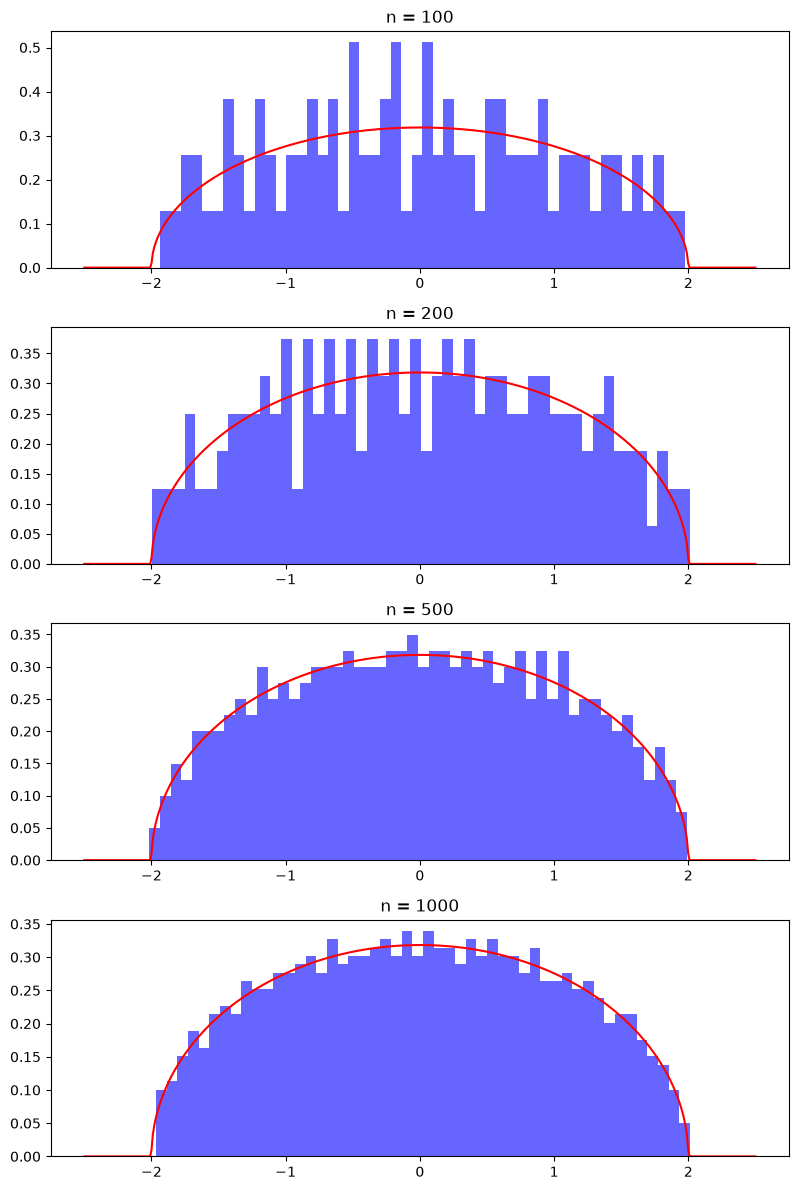

In [32]:
import matplotlib.pyplot as plt

ns = [100, 200, 500, 1000]
x = np.linspace(-2.5, 2.5, 500)
pdf = wigner_density(x)

fig, axes = plt.subplots(4, 1, figsize=(8, 12))

for ax, n in zip(axes, ns):
    mat = generate_wigner(n)
    eig = get_spectrum(mat)
    ax.hist(eig, bins=50, density=True, alpha=0.6, color="blue")
    ax.plot(x, pdf, color="red")
    ax.set_title(f"n = {n}")

plt.tight_layout()
plt.show()


从图中可以看到，n=100、200 时直方图波动较大；当 n 大约达到 500 以后，特征值分布已经较好地贴合半圆密度曲线，n=1000 拟合效果最佳。


In [33]:
def is_valid_board(board):
    if board.ndim != 2:
        return False
    if not np.all(np.isin(board, [0, 1])):
        return False
    return True


In [34]:
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("输入不是有效的生命游戏棋盘")
    m, n = board.shape
    new_board = np.zeros_like(board)
    # 环绕边界，用 roll 计算邻居和
    neighbor_sum = (
        np.roll(board, 1, axis=0) + np.roll(board, -1, axis=0) +
        np.roll(board, 1, axis=1) + np.roll(board, -1, axis=1) +
        np.roll(np.roll(board, 1, axis=0), 1, axis=1) +
        np.roll(np.roll(board, 1, axis=0), -1, axis=1) +
        np.roll(np.roll(board, -1, axis=0), 1, axis=1) +
        np.roll(np.roll(board, -1, axis=0), -1, axis=1)
    )
    # 规则
    alive = board == 1
    dead = board == 0
    # 活细胞：2或3邻居存活
    new_board[alive & ((neighbor_sum == 2) | (neighbor_sum == 3))] = 1
    # 死细胞：恰好3邻居复活
    new_board[dead & (neighbor_sum == 3)] = 1
    return new_board


In [35]:
def draw_gol_board(board):
    if not is_valid_board(board):
        raise ValueError("输入不是有效的生命游戏棋盘")
    plt.figure()
    plt.imshow(board, cmap="gray_r", vmin=0, vmax=1)
    plt.xticks([])
    plt.yticks([])
    plt.show()


原始棋盘：
[[0 0 0 0 0]
 [0 0 0 0 0]
 [0 1 1 1 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]

下一步：
[[0 0 0 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 1 0 0]
 [0 0 0 0 0]]


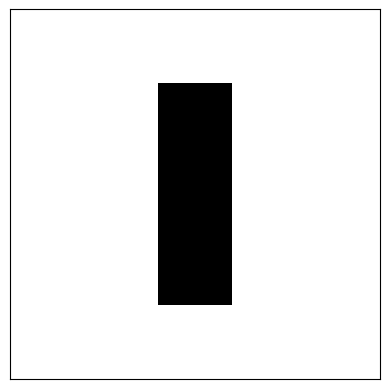

In [36]:
# 测试棋盘：一个简单的 blinker（闪烁振荡器）
test_board = np.zeros((5, 5), dtype=int)
test_board[2, 1:4] = 1
print("原始棋盘：")
print(test_board)

step1 = gol_step(test_board)
print("\n下一步：")
print(step1)

draw_gol_board(step1)


In [37]:
import pandas as pd

df = pd.read_csv("iris.csv", index_col=0)
# 按标准顺序补充物种列（不改动原始测量数据）
df["species"] = ["setosa"]*50 + ["versicolor"]*50 + ["virginica"]*50

print("数据点数：", len(df))
print("\n列名：")
print(df.columns.tolist())
print("\n各列数据类型：")
print(df.dtypes)
print("\n花卉种类数量：", df["species"].nunique())
print("\n前几行：")
print(df.head())


数据点数： 150

列名：
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'species']

各列数据类型：
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species                  str
dtype: object

花卉种类数量： 3

前几行：
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  


In [38]:
# 索引34（原第35行）：改为 4.9, 3.1, 1.5, 0.2, setosa
df.loc[34, ["sepal length (cm)", "sepal width (cm)", "petal length (cm)", "petal width (cm)"]] = [4.9, 3.1, 1.5, 0.2]
# 索引37（原第38行）：改为 4.9, 3.6, 1.4, 0.1, setosa
df.loc[37, ["sepal length (cm)", "sepal width (cm)", "petal length (cm)", "petal width (cm)"]] = [4.9, 3.6, 1.4, 0.1]

# 检查修改后的两行
print("索引34：")
print(df.loc[34])
print("\n索引37：")
print(df.loc[37])


索引34：
sepal length (cm)       4.9
sepal width (cm)        3.1
petal length (cm)       1.5
petal width (cm)        0.2
species              setosa
Name: 34, dtype: object

索引37：
sepal length (cm)       4.9
sepal width (cm)        3.6
petal length (cm)       1.4
petal width (cm)        0.1
species              setosa
Name: 37, dtype: object


In [39]:
df["Petal.Ratio"] = df["petal length (cm)"] / df["petal width (cm)"]
df["Sepal.Ratio"] = df["sepal length (cm)"] / df["sepal width (cm)"]

print(df[["Petal.Ratio", "Sepal.Ratio"]].head())


   Petal.Ratio  Sepal.Ratio
0          7.0     1.457143
1          7.0     1.633333
2          6.5     1.468750
3          7.5     1.483871
4          7.0     1.388889


In [40]:
df.to_csv("iris_corrected.csv")
print("已保存 iris_corrected.csv")


已保存 iris_corrected.csv


In [41]:
group_stat = df.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
print(group_stat)


           Petal.Ratio                                     Sepal.Ratio  \
                  mean    median       min   max       std        mean   
species                                                                  
setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.471380   
versicolor    3.182408  3.230769  0.335714   4.1  0.515861    2.165531   
virginica     2.780662  2.666667  2.125000   4.0  0.407367    2.230453   

                                                    
              median       min       max       std  
species                                             
setosa      1.466667  1.268293  1.956522  0.119677  
versicolor  2.161290  1.764706  2.818182  0.228104  
virginica   2.169540  1.823529  2.961538  0.246992  
